<a href="https://colab.research.google.com/github/twyeh/solid-state-physics/blob/main/phonopy_example1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install phonopy
!pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.5/897.5 kB 6.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 10.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 979.1/979.1 kB 12.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [phonopy]


/usr/local/lib/python3.13/dist-packages/phonopy/cui/load.py:280: PrimitiveMatrixAutoDefaultWarning: primitive_matrix defaulted to 'auto' and was resolved to a non-identity matrix:
  [ 0.00000,  0.00000, -1.00000]
  [-1.00000,  0.00000,  0.00000]
  [ 1.00000,  1.00000,  1.00000]
This differs from phonopy v3, whose default was the identity matrix. Pass primitive_matrix='P' (or --pa P on the command line) to restore the v3 behaviour.
  phonon = Phonopy(


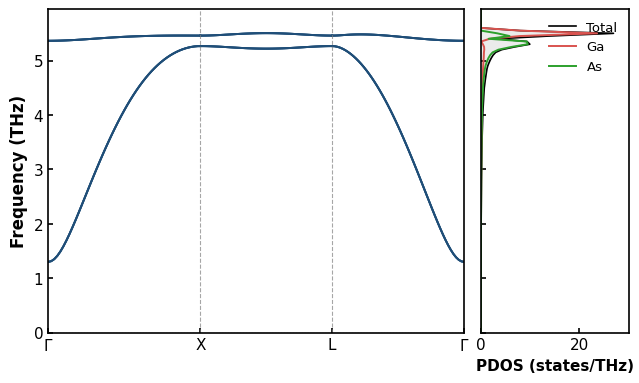

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import phonopy
import os

# ==========================================
# 0. 清除可能殘留的舊 FORCE_SETS 檔案並自動產生模擬的 POSCAR 檔案
# ==========================================
if os.path.exists("FORCE_SETS"):
    os.remove("FORCE_SETS")

poscar_content = """GaAs Zincblende Structure
5.65
0.0 0.5 0.5
0.5 0.0 0.5
0.5 0.5 0.0
Ga As
1 1
Direct
0.0 0.0 0.0
0.25 0.25 0.25
"""
with open("POSCAR", "w") as f:
    f.write(poscar_content)

# ==========================================
# 1. 載入晶體結構
# ==========================================
phonon = phonopy.load(
    supercell_matrix=[2, 2, 2],
    primitive_matrix="auto",
    unitcell_filename="POSCAR"
)

# ==========================================
# 2. 設定模擬的二階力常數 (Force Constants)
# ==========================================
num_atoms = len(phonon.supercell)
force_constants = np.zeros((num_atoms, num_atoms, 3, 3), dtype='double')

for i in range(num_atoms):
    force_constants[i, i, 0, 0] = 8.0
    force_constants[i, i, 1, 1] = 8.0
    force_constants[i, i, 2, 2] = 8.0
    for j in range(num_atoms):
        if i != j:
            force_constants[i, j, 0, 0] = -0.5
            force_constants[i, j, 1, 1] = -0.5
            force_constants[i, j, 2, 2] = -0.5

phonon.force_constants = force_constants

# ==========================================
# 3. 設定布里淵區高對稱路徑並計算能帶
# ==========================================
# 高對稱點座標：Γ -> X -> L -> Γ
path_points = [
    [0.0, 0.0, 0.0],
    [0.5, 0.0, 0.5],
    [0.5, 0.5, 0.5],
    [0.0, 0.0, 0.0]
]
labels = [r"$\Gamma$", "X", "L", r"$\Gamma$"]

# 將路徑切分為多個段落 (Segments)
paths = []
for i in range(len(path_points) - 1):
    start = np.array(path_points[i])
    end = np.array(path_points[i+1])
    segment = [start + t * (end - start) for t in np.linspace(0, 1, 51)]
    paths.append(segment)

phonon.run_band_structure(paths)
bands = phonon.band_structure

# ==========================================
# 4. 計算總態密度（DOS）與投影態密度（PDOS）
# ==========================================
phonon.run_mesh([15, 15, 15], with_eigenvectors=True, is_mesh_symmetry=False)
phonon.run_total_dos(freq_min=0, freq_max=15, freq_pitch=0.05)
phonon.run_projected_dos(freq_min=0, freq_max=15, freq_pitch=0.05)

total_dos_obj = phonon.total_dos
projected_dos_obj = phonon.projected_dos

# 依照化學元素自動將原胞內同種原子 PDOS 加總
symbols = phonon.primitive.symbols
unique_elements = list(dict.fromkeys(symbols))

freq_dos = total_dos_obj.frequency_points
total_dos = total_dos_obj.dos
pdos_data = projected_dos_obj.projected_dos

element_pdos = {el: np.zeros_like(freq_dos) for el in unique_elements}
for idx, el in enumerate(symbols):
    element_pdos[el] += pdos_data[idx]

# ==========================================
# 5. 出版級 Matplotlib 雙面板左右對齊繪圖
# ==========================================
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.linewidth": 1.2,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2,
    "mathtext.default": "regular"
})

fig, (ax_band, ax_dos) = plt.subplots(
    1, 2, figsize=(7.5, 4.2),
    gridspec_kw={"width_ratios": [2.8, 1], "wspace": 0.06},
    sharey=True
)

# --- 左圖：聲子能帶結構 ---
distances_list = bands.distances
frequencies_list = bands.frequencies

# 逐段繪製能帶
for dists, freqs in zip(distances_list, frequencies_list):
    for branch in freqs.T:
        ax_band.plot(dists, branch, color="#1f4e78", linewidth=1.4)

# 收集各高對稱轉折點在 X 軸上的絕對坐標
tick_positions = []
tick_positions.append(distances_list[0][0])
for dists in distances_list:
    tick_positions.append(dists[-1])

# 畫高對稱點垂直分割線
for pos in tick_positions[1:-1]:
    ax_band.axvline(x=pos, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)

ax_band.set_xticks(tick_positions)
ax_band.set_xticklabels(labels)
ax_band.set_xlim(distances_list[0][0], distances_list[-1][-1])
ax_band.set_ylabel("Frequency (THz)", fontsize=12, fontweight="bold")
ax_band.axhline(y=0, color="black", linestyle=":", linewidth=0.8)

# --- 右圖：總態密度與元素投影態密度 ---
ax_dos.plot(total_dos, freq_dos, color="black", linewidth=1.2, label="Total")
ax_dos.fill_betweenx(freq_dos, 0, total_dos, color="lightgray", alpha=0.45)

colors = ["#d9534f", "#2ca02c", "#ff7f0e", "#9467bd"]
for i, el in enumerate(unique_elements):
    ax_dos.plot(
        element_pdos[el], freq_dos,
        color=colors[i % len(colors)], linewidth=1.4, label=el
    )

ax_dos.set_xlim(0, np.max(total_dos) * 1.12)
ax_dos.set_xlabel("PDOS (states/THz)", fontsize=11, fontweight="bold")
ax_dos.axhline(y=0, color="black", linestyle=":", linewidth=0.8)
ax_dos.legend(frameon=False, loc="upper right", fontsize=9.5)

# 設定 Y 軸顯示範圍
flat_freqs = np.concatenate(frequencies_list)
y_min = min(0, np.min(flat_freqs) * 1.05)
y_max = np.max(flat_freqs) * 1.08
ax_band.set_ylim(y_min, y_max)

# 輸出高解析度向量圖與點陣圖
plt.savefig("phonon_band_pdos.pdf", bbox_inches="tight", dpi=600)
plt.savefig("phonon_band_pdos.png", bbox_inches="tight", dpi=600)
plt.show()

In [10]:
from google.colab import files

# 自動觸發下載產生的出版級 PDF 圖表
try:
    files.download('phonon_band_pdos.pdf')
    print("已成功啟動 'phonon_band_pdos.pdf' 的下載！")
except Exception as e:
    print(f"下載失敗: {e}。您也可以手動從左側檔案面板下載此檔案。")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

已成功啟動 'phonon_band_pdos.pdf' 的下載！
